# Workshop 02

# YOLOv8 Object Detection Using Laptop Camera

## Aim
To capture an image using the laptop camera and perform object detection using YOLOv8.

## Step 1: Import Required Libraries

Import OpenCV, Matplotlib, YOLO, and other required libraries.

In [1]:
!pip install ultralytics opencv-python matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 35.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


In [2]:
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO
import numpy as np

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


## Step 2: Load YOLOv8 Model

Load the pretrained YOLOv8 Nano model.

In [3]:
model = YOLO('yolov8n.pt')

## Step 3: Open Laptop Camera

Access the laptop camera using OpenCV.

In [9]:
import time
import cv2
import matplotlib.pyplot as plt

from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode

# Capture image from laptop camera
def capture_image():
    js = Javascript('''
        async function captureImage() {
            const video = document.createElement('video');

            const stream = await navigator.mediaDevices.getUserMedia({
                video: true
            });

            video.srcObject = stream;
            await video.play();

            document.body.appendChild(video);

            // Wait for 5 seconds
            await new Promise(resolve => setTimeout(resolve, 5000));

            // Capture one image
            const canvas = document.createElement('canvas');
            canvas.width = video.videoWidth;
            canvas.height = video.videoHeight;

            canvas.getContext('2d').drawImage(video, 0, 0);

            stream.getTracks().forEach(track => track.stop());
            video.remove();

            return canvas.toDataURL('image/jpeg');
        }

        captureImage();
    ''')

    display(js)
    data = eval_js('captureImage()')

    # Decode captured image
    binary = b64decode(data.split(',')[1])

    with open('captured_image.jpg', 'wb') as f:
        f.write(binary)

    return cv2.imread('captured_image.jpg')




## Step 4: Capture Image

Wait for 5 seconds and capture one image from the laptop camera.

Camera will capture an image after 5 seconds...


<IPython.core.display.Javascript object>

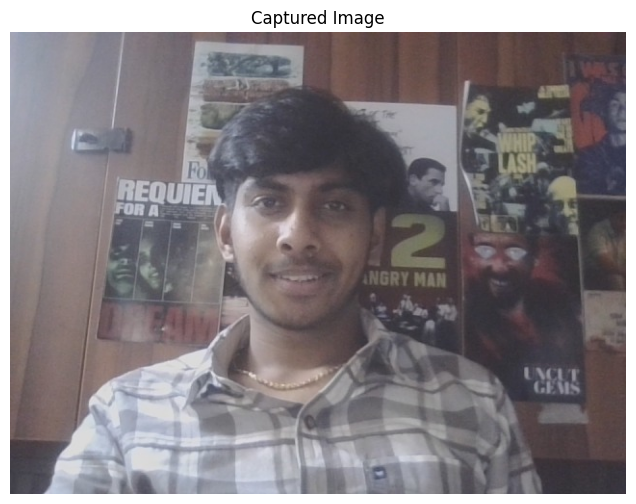

Image captured successfully!


In [19]:
# Capture image
print("Camera will capture an image after 5 seconds...")
frame = capture_image()

# Display captured image
img = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(8, 6))
plt.imshow(img)
plt.title("Captured Image")
plt.axis('off')
plt.show()

print("Image captured successfully!")

## Step 5: Perform Object Detection

Apply YOLOv8 to the captured image.


0: 480x640 2 persons, 1 refrigerator, 306.4ms
Speed: 6.9ms preprocess, 306.4ms inference, 17.6ms postprocess per image at shape (1, 3, 480, 640)


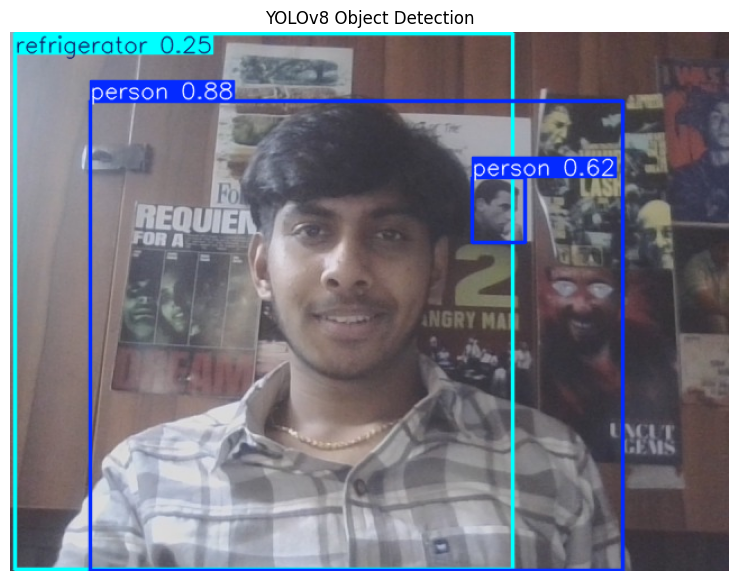

In [20]:
# Load captured image
img = cv2.imread('captured_image.jpg')

# Apply YOLOv8 object detection
results = model(img)

# Draw bounding boxes and labels
detected_img = results[0].plot()

# Convert BGR to RGB
detected_img = cv2.cvtColor(detected_img, cv2.COLOR_BGR2RGB)

# Display detected image
plt.figure(figsize=(10, 7))
plt.imshow(detected_img)
plt.title("YOLOv8 Object Detection")
plt.axis('off')
plt.show()

## Step 6: Display Detected Image

Display the image with bounding boxes and object labels.

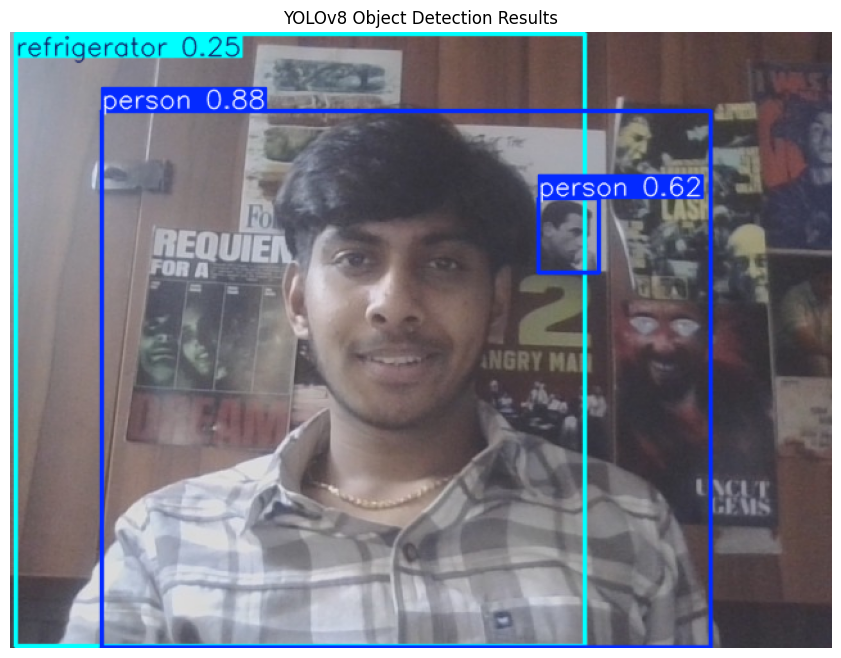

In [21]:
detected_image = results[0].plot()

# Convert BGR to RGB
detected_image = cv2.cvtColor(
    detected_image, cv2.COLOR_BGR2RGB
)

# Display detected image
plt.figure(figsize=(12, 8))
plt.imshow(detected_image)
plt.title("YOLOv8 Object Detection Results")
plt.axis('off')
plt.show()

## Step 7: Release Camera

Release the laptop camera after capturing the image.

In [22]:
# Release camera
if 'cap' in globals() and cap.isOpened():
    cap.release()

# Close all OpenCV windows
cv2.destroyAllWindows()

print("Camera released successfully!")

Camera released successfully!


In [24]:
# Save detected image
cv2.imwrite('detected_output.jpg', results[0].plot())

# Download detected image
files.download('detected_output.jpg')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>